In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import statsmodels.api as sm

%matplotlib inline

In [2]:
df = pd.read_csv('../../day1/lab-eda-univariate/amz_uk_processed_data.csv')

In [3]:
df.head()

,asin,title,imgUrl,productURL,stars,reviews,price,isBestSeller,boughtInLastMonth,categoryName
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",https://m.media-amazon.com/images/I/71C3lbbeLs...,https://www.amazon.co.uk/dp/B09B96TG33,4.7,15308,21.99,False,0,Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",https://m.media-amazon.com/images/I/61c5rSxwP0...,https://www.amazon.co.uk/dp/B01HTH3C8S,4.7,98099,23.99,True,0,Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",https://m.media-amazon.com/images/I/61j3SEUjMJ...,https://www.amazon.co.uk/dp/B09B8YWXDF,4.7,15308,21.99,False,0,Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",https://m.media-amazon.com/images/I/71yf6yTNWS...,https://www.amazon.co.uk/dp/B09B8T5VGV,4.7,7205,31.99,False,0,Hi-Fi Speakers
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,https://m.media-amazon.com/images/I/613dEoF9-r...,https://www.amazon.co.uk/dp/B09WX6QD65,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.columns

Index(['asin', 'title', 'imgUrl', 'productURL', 'stars', 'reviews', 'price',
       'isBestSeller', 'boughtInLastMonth', 'categoryName'],
      dtype='str')

In [5]:
df = df.rename(columns={'categoryName': 'category'})

In [6]:
# Crosstab Analysis:
# Create a crosstab between the product category and the isBestSeller status

ct = pd.crosstab(df['category'], df['isBestSeller'])
ct

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4020,2
Abrasive & Finishing Products,245,5
Action Cameras,1014,0
Adapters,248,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,16101,183


In [7]:
# Are there categories where being a best-seller is more prevalent?
# Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

ct_sorted=ct.copy()
ct_sorted ['prop_bestseller'] = ct_sorted[True] / (ct_sorted[True] + ct_sorted[False])
ct_sorted = ct_sorted.sort_values('prop_bestseller', ascending=False)
ct_sorted

isBestSeller,False,True,prop_bestseller
category,,,
Health & Personal Care,7750,485,0.058895
Grocery,5964,313,0.049865
Mobile Phone Accessories,244,10,0.039370
Power & Hand Tools,6212,243,0.037645
"Billiard, Snooker & Pool",241,8,0.032129
...,...,...,...
Cameras,12,0,0.000000
Outdoor Rope Lights,3911,0,0.000000
Computer Cases,222,0,0.000000


In [8]:
df.groupby('category')['isBestSeller'].mean().sort_values(ascending=False)

category
Health & Personal Care         0.058895
Grocery                        0.049865
Mobile Phone Accessories       0.039370
Power & Hand Tools             0.037645
Billiard, Snooker & Pool       0.032129
                                 ...   
Cameras                        0.000000
Outdoor Rope Lights            0.000000
Computer Cases                 0.000000
Motorbike Seat Covers          0.000000
eBook Readers & Accessories    0.000000
Name: isBestSeller, Length: 296, dtype: float64

In [9]:
#Statistical Tests:
# Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
from scipy.stats import chi2_contingency

chi2_statistic, chi2_p_value, _, expected_freq = chi2_contingency(ct)

chi2_statistic, chi2_p_value, expected_freq

(np.float64(33019.04971964154),
 np.float64(0.0),
 array([[2.47328548e+02, 6.71451747e-01],
        [4.01111057e+03, 1.08894312e+01],
        [2.49323133e+02, 6.76866681e-01],
        [1.01125463e+03, 2.74537126e+00],
        [2.50320426e+02, 6.79574148e-01],
        [8.01424280e+03, 2.17572026e+01],
        [6.88131848e+01, 1.86815204e-01],
        [1.99458507e+02, 5.41493345e-01],
        [5.74041582e+03, 1.55841785e+01],
        [1.08036700e+04, 2.93299870e+01],
        [9.03347577e+03, 2.45242336e+01],
        [2.35361038e+02, 6.38962147e-01],
        [2.97392633e+03, 8.07366577e+00],
        [9.45134134e+03, 2.56586621e+01],
        [6.67886810e+03, 1.81319046e+01],
        [5.17594825e+02, 1.40517523e+00],
        [1.48397129e+04, 4.02871048e+01],
        [2.61988748e+03, 7.11251508e+00],
        [2.53312303e+02, 6.87696548e-01],
        [4.02906183e+02, 1.09381656e+00],
        [5.85610176e+03, 1.58982446e+01],
        [3.10656624e+03, 8.43375884e+00],
        [2.02450384e+02, 5

The null hypothesis of the Chi-square test is that the two categorical variables are independent. Given the extremely low \( p \)-value, we reject the null hypothesis. This implies that there's a significant association between `category` and `best-seller status` in the dataset.

In [10]:
# Compute Cramér's V to understand the strength of association between best-seller status and category.
from scipy.stats.contingency import association

association(ct, method="cramer")

0.1218814906639688

The Cramér's V value of 0.121 suggests a weak association between the two variables. Though statistically significant, the strength of this relationship is not very strong in practical terms.

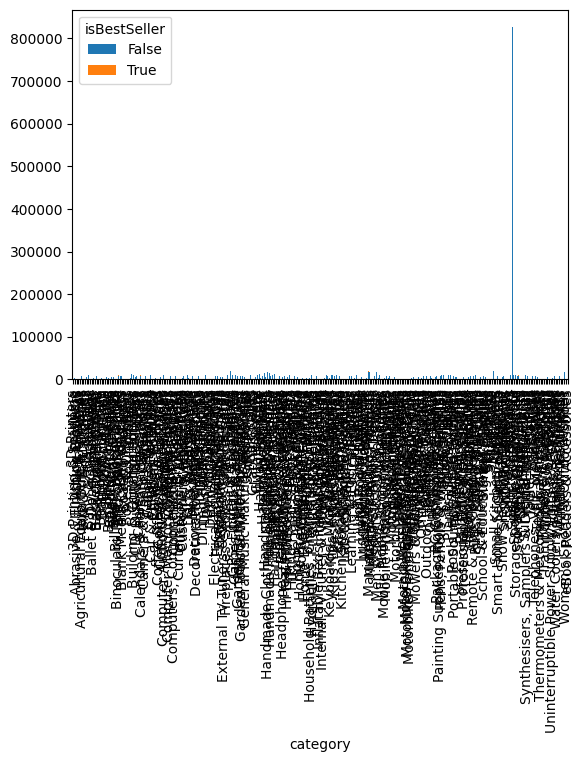

In [11]:
# 3. Visualizations:
# Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

ct.plot(kind="bar", stacked=True);

<Axes: xlabel='category'>

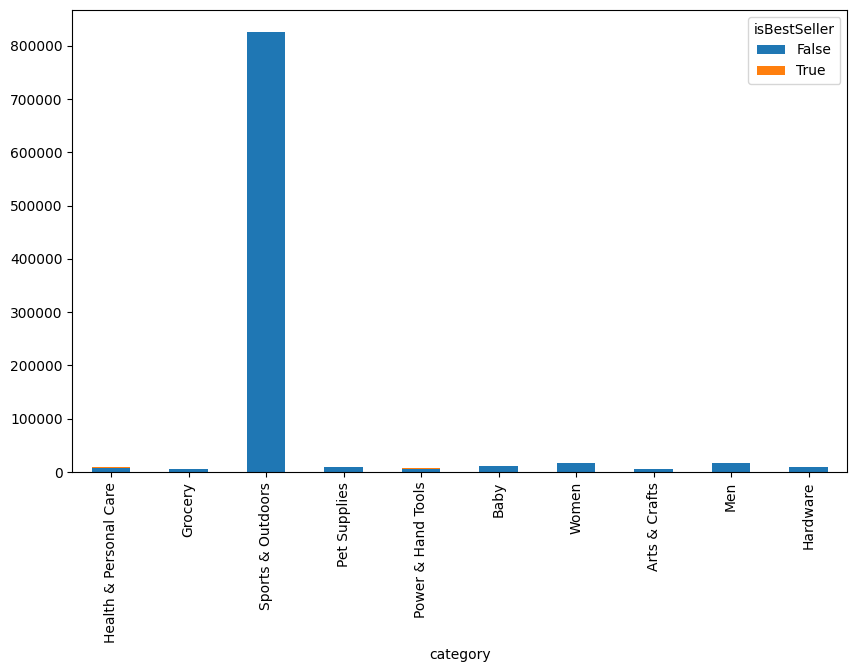

In [14]:
# As there were too many categories for the graph to be representative let's do the bar chart with only the top 10 categories:
ct_prop_top10 = (ct.sort_values(True, ascending=False).head(10))

ct_prop_top10.plot(kind='bar',stacked=True,figsize=(10, 6))

In [16]:
#Objective: Investigate how different product categories influence product prices.
#Preliminary Step: Remove outliers in product prices.
#For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
#Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower_whisker = Q1 - 1.5 * IQR
upper_whisker = Q3 + 1.5 * IQR

df_no_outliers = df[(df['price'] >= lower_whisker) &(df['price'] <= upper_whisker)]

print(f'Original rows: {len(df)}')
print(f'Rows after removing outliers: {len(df_no_outliers)}')

Original rows: 2222742
Rows after removing outliers: 1918647


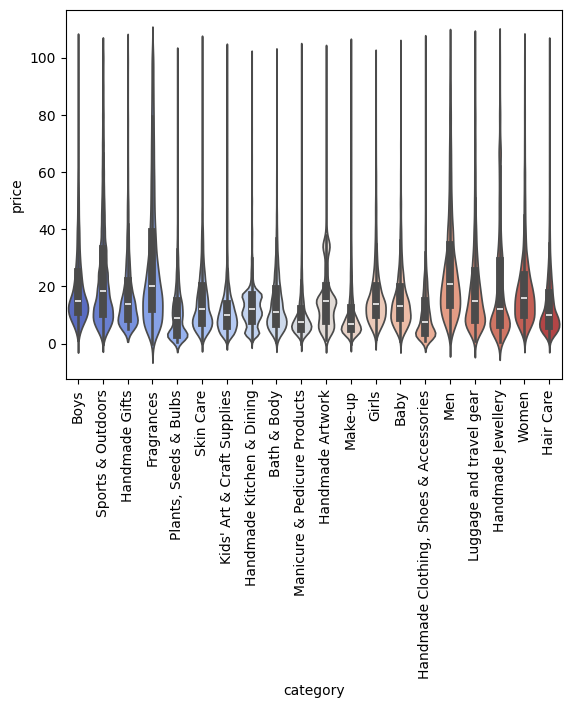

In [17]:
# Violin Plots:
# Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.

top20_categories = (df_no_outliers['category'].value_counts().head(20).index)

df_top20 = df_no_outliers[df_no_outliers['category'].isin(top20_categories)]

sns.violinplot(data=df_top20,x='category',y='price',palette='coolwarm',hue='category',legend=False)
plt.xticks(rotation=90)
plt.show()

In [18]:
# Which product category tends to have the highest median price? Don't filter here by top categories.

median_prices = (df_no_outliers.groupby('category')['price'].median().sort_values(ascending=False))

median_prices.idxmax(), median_prices.max()

('Desktop PCs', np.float64(75.0))

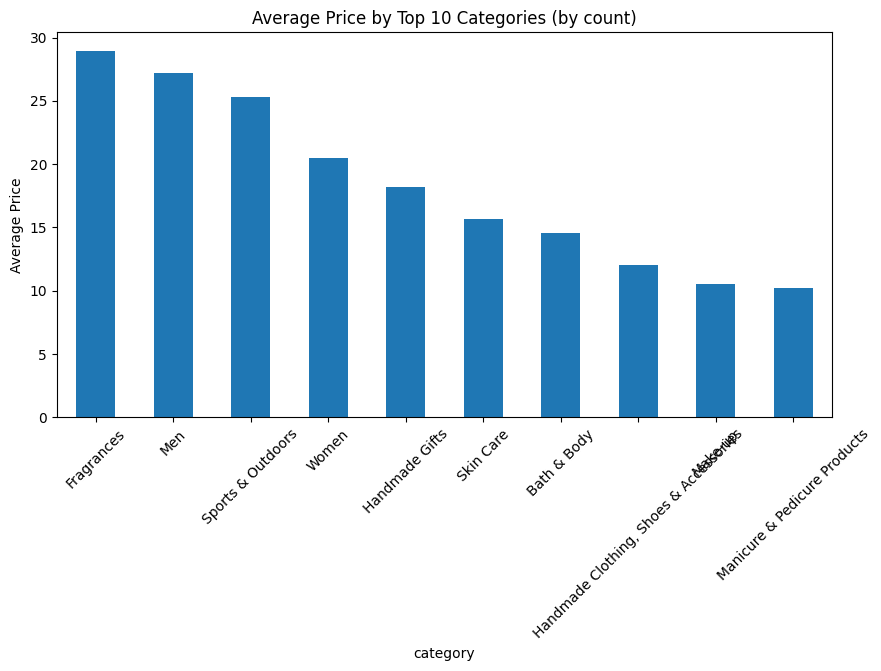

In [19]:
# Bar Charts:
# Create a bar chart comparing the average price of products for the top 10 product categories (based on count).

top10_categories = (df_no_outliers['category'].value_counts().head(10).index)

df_top10 = df_no_outliers[df_no_outliers['category'].isin(top10_categories)]

avg_price_top10 = (df_top10.groupby('category')['price'].mean().sort_values(ascending=False))

avg_price_top10.plot(kind='bar', figsize=(10,5))
plt.ylabel('Average Price')
plt.title('Average Price by Top 10 Categories (by count)')
plt.xticks(rotation=45)
plt.show()

In [20]:
# Which product category commands the highest average price? Don't filter here by top categories.

avg_price_all = (df_no_outliers.groupby('category')['price'].mean().sort_values(ascending=False))

avg_price_all.idxmax(), avg_price_all.max()

('Motherboards', np.float64(70.10207792207792))

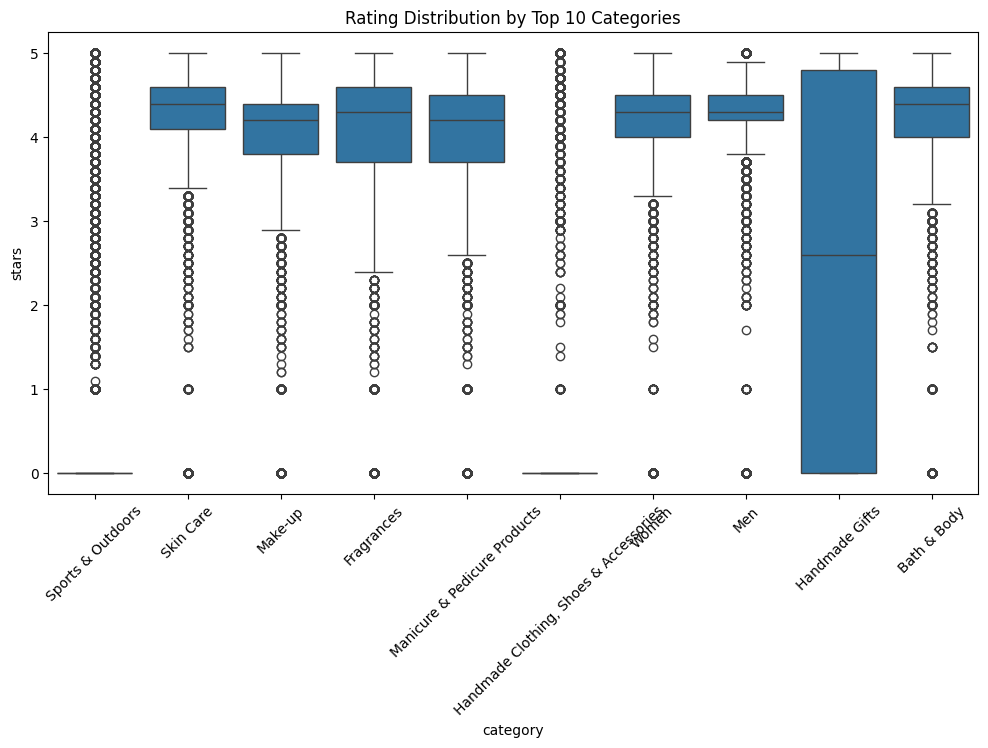

In [21]:
# Box Plots:
# Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.

top10_categories = (df_no_outliers['category'].value_counts().head(10).index)

df_top10 = df_no_outliers[df_no_outliers['category'].isin(top10_categories)]

plt.figure(figsize=(12, 6))

sns.boxplot(data=df_top10,x='category',y='stars', order=top10_categories)

plt.xticks(rotation=45)
plt.title('Rating Distribution by Top 10 Categories')
plt.show()

In [22]:
# Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

median_ratings = (df_no_outliers.groupby('category')['stars'].median().sort_values(ascending=False))

median_ratings.idxmax(), median_ratings.max()

('Computer Memory', np.float64(4.7))

In [23]:
# Part 3: Investigating the Interplay Between Product Prices and Ratings
# Objective: Analyze how product ratings (stars) correlate with product prices.
# Correlation Coefficients:
# Calculate the correlation coefficient between price and stars.

correlation = df_no_outliers['price'].corr(df_no_outliers['stars'])
print(correlation)

-0.0661732399075169


**Is there a significant correlation between product price and its rating?**

Correlation = -0.066, which indicates a very weak negative correlation between product price and customer rating.
The correlation is negative, meaning that as price increases, ratings tend to decrease slightly.
However, the magnitude is very close to zero (|-0.066| < 0.1), so the relationship is extremely weak.
In practical terms, there is little to no linear relationship between a product's price and its star rating.

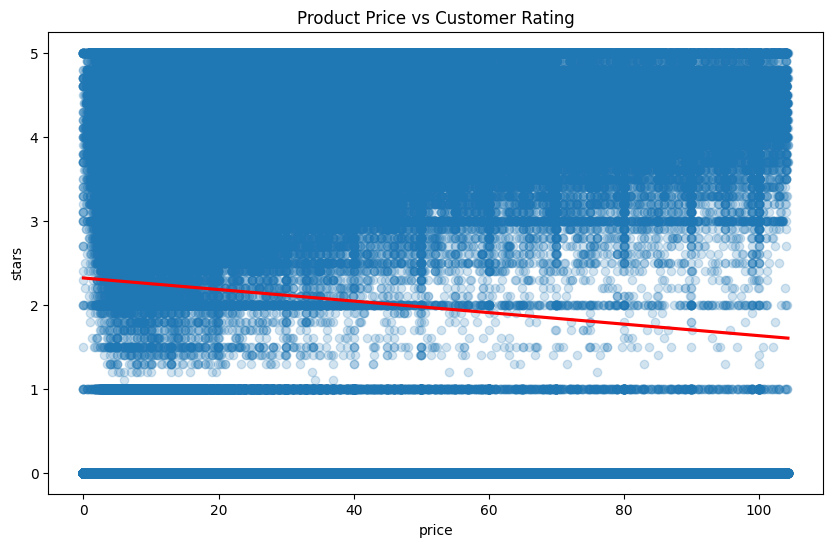

In [24]:
# Visualizations:
# Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_no_outliers,
    x='price',
    y='stars',
    scatter_kws={'alpha': 0.2},
    line_kws={'color': 'red'}
)

plt.title('Product Price vs Customer Rating')
plt.show()

The scatter plot shows a very weak negative relationship between product price and customer ratings, as indicated by the slightly downward-sloping trend line. However, the points are widely dispersed across all price levels, suggesting that price has little influence on how customers rate products, which is consistent with the correlation coefficient of -0.066.

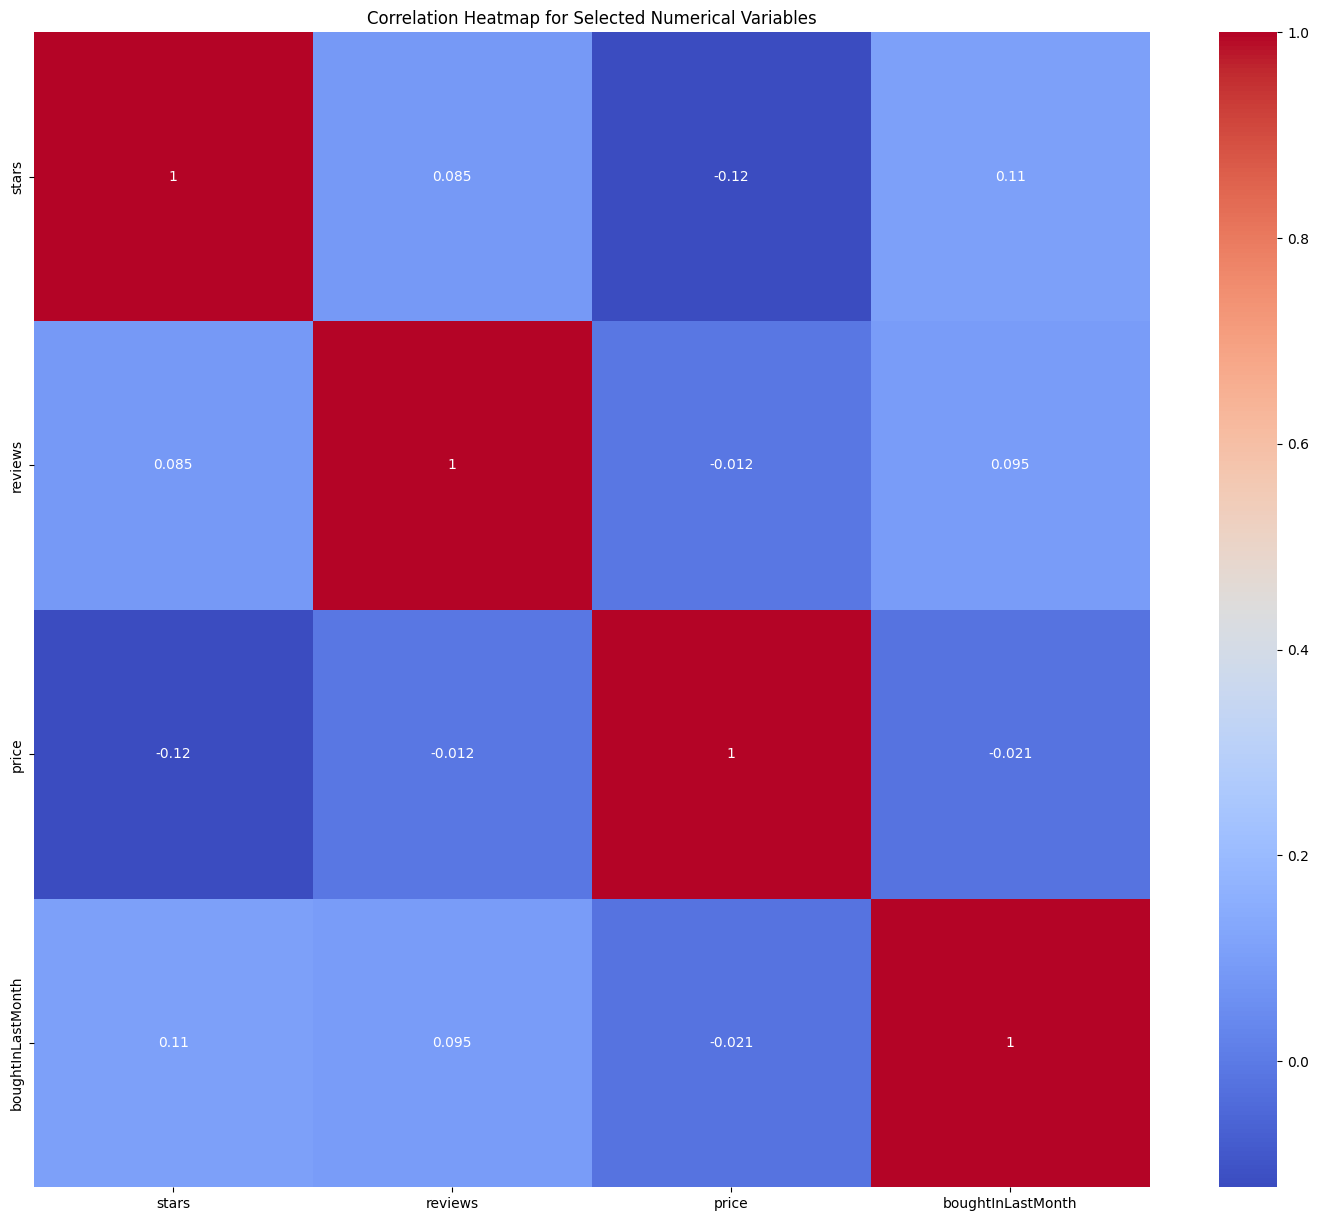

In [25]:
# Use a correlation heatmap to visualize correlations between all numerical variables.

potential_categorical_from_numerical = df.select_dtypes("number").loc[:, df.select_dtypes("number").nunique() < 20]
df_numerical = df.select_dtypes("number").drop(columns=potential_categorical_from_numerical.columns)
correlation_matrix = df_numerical.corr()


plt.figure(figsize=(18, 15))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")
plt.title('Correlation Heatmap for Selected Numerical Variables')
plt.show()

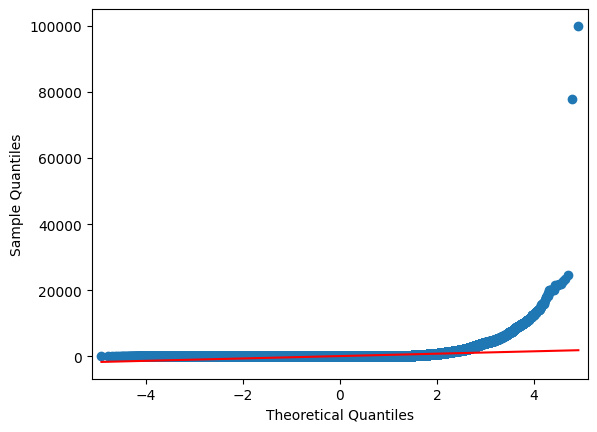

In [28]:
# Examine if product prices typically follow a normal distribution using a QQ plot.

sm.qqplot(df['price'], line='s');

The 'price' data is not normally distributed. It appears to be right-skewed with potential outliers on the higher end and has heavier tails than a normal distribution.